# Data Analysis Bitcoin

In [ ]:
!pip install yfinance

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime as dt
from math import sqrt
from sklearn.metrics import mean_squared_error

In [ ]:
start = dt(2010,1,1)
end = dt(2024,1,1)
symbol = 'BTC-USD'

In [ ]:
btc = yf.download(symbol,start=start,end=end)

# Remove the fields of no use in the future price prediction
# btc = btc.drop(columns = ['Adj Close', 'Volume'])

btc.head()

print('\n', "Shape of Dataset:", btc.shape)
btc.head()

[*********************100%***********************]  1 of 1 completed



 Shape of Dataset: (3393, 5)


Price,Close,High,Low,Open,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
Date,,,,,
2014-09-17,457.334015,468.174011,452.421997,465.864014,21056800
2014-09-18,424.440002,456.859985,413.104004,456.859985,34483200
2014-09-19,394.795990,427.834991,384.532013,424.102997,37919700
2014-09-20,408.903992,423.295990,389.882996,394.673004,36863600
2014-09-21,398.821014,412.425995,393.181000,408.084991,26580100


In [ ]:
# Remove the rows who has a Null value for any of the fields
btc = btc.dropna()
print("Shape of Dataset:", btc.shape)

Shape of Dataset: (3393, 4)


In [ ]:
# Adjust these weights as needed
weights = {'Open': 0.25, 'Close': 0.25, 'High': 0.25, 'Low': 0.25}

# Calculate the weighted average for each row
btc['Weighted_Price'] = (btc['Open'] * weights['Open'] +
                       btc['Close'] * weights['Close'] +
                       btc['High'] * weights['High'] +
                       btc['Low'] * weights['Low'])

# Display the DataFrame with the new 'Weighted_Avg' column
btc.head()

Price,Close,High,Low,Open,Weighted_Price
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,
Date,,,,,
2014-09-17 00:00:00+00:00,457.334015,468.174011,452.421997,465.864014,460.948509
2014-09-18 00:00:00+00:00,424.440002,456.859985,413.104004,456.859985,437.815994
2014-09-19 00:00:00+00:00,394.795990,427.834991,384.532013,424.102997,407.816498
2014-09-20 00:00:00+00:00,408.903992,423.295990,389.882996,394.673004,404.188995
2014-09-21 00:00:00+00:00,398.821014,412.425995,393.181000,408.084991,403.128250


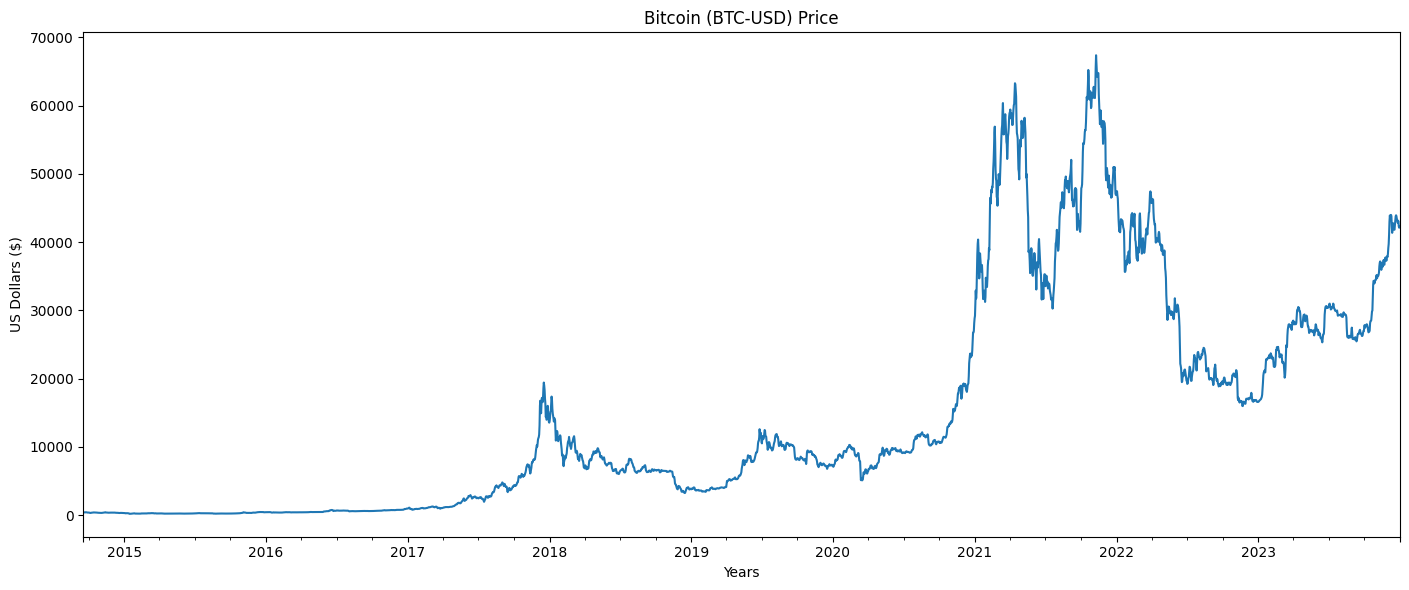

In [ ]:
# Plot the BtC price graph over the span of dataset
btc.Weighted_Price.plot(title = "Bitcoin (BTC-USD) Price", figsize=(14,6))
plt.tight_layout()
plt.xlabel('Years')
plt.ylabel('US Dollars ($)')
plt.show()

Shape of Dataset: (2555, 5)


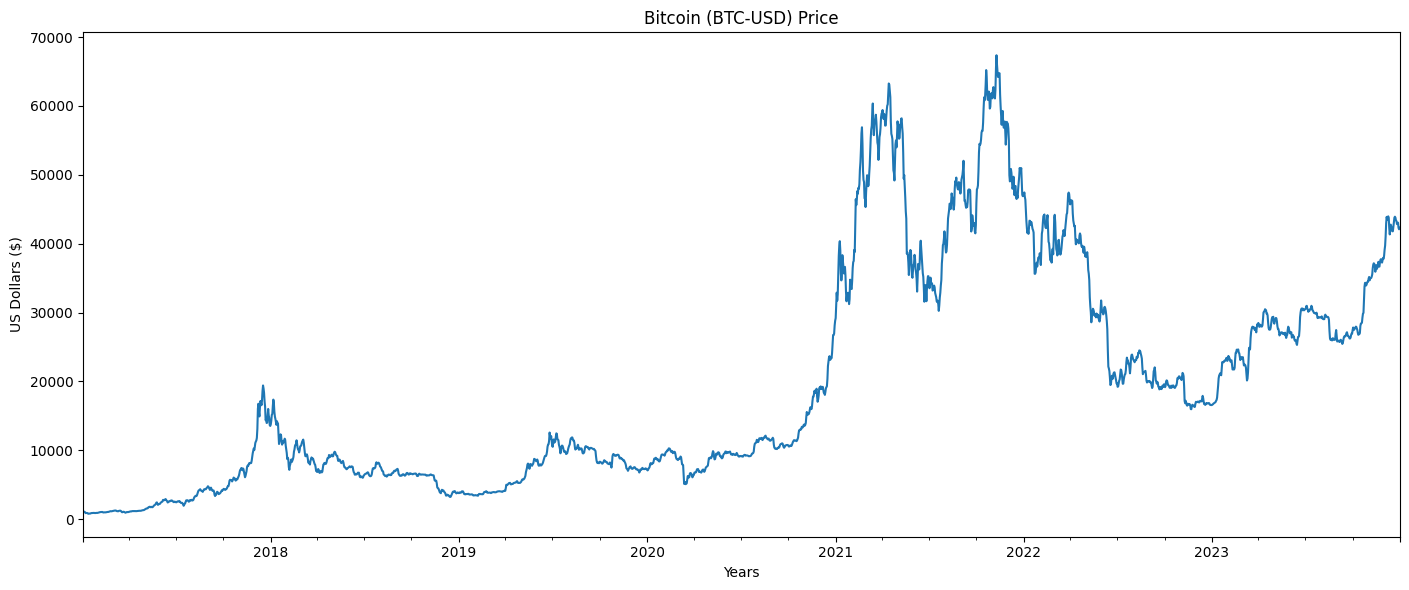

In [ ]:
# Initial years do not define the volatility, hence will constrict the dataset
btc = btc.tail(365*7)

print("Shape of Dataset:", btc.shape)

# Relevant data plot
btc.Weighted_Price.plot(title = "Bitcoin (BTC-USD) Price", figsize=(14,6))
plt.tight_layout()
plt.xlabel('Years')
plt.ylabel('US Dollars ($)')
plt.show()

# ARIMA Model

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

In [ ]:
arima_btc = btc['Weighted_Price']

# Split the dataset into 70% training data and 30% testing data
X_values = arima_btc.values
datesX = arima_btc.index
split_index = int(len(X_values) * 0.7)
train_data, test_data = X_values[:split_index], X_values[split_index:]
plotDates = datesX[split_index:len(X_values)]

len(test_data)

767

In [ ]:
# Next we will forecast with ARIMA using 5,1,0
stationary_data = list()
for i in range(365, len(train_data)):
    value = train_data[i] - train_data[i-365]
    stationary_data.append(value)

# fit model
model = ARIMA(stationary_data, order=(5, 1, 0))
model_fit = model.fit()
arima_btc_forecast = model_fit.predict(start=len(stationary_data), end=len(stationary_data)+766)


training_history = [x for x in train_data]
day = 1
arima_btc_predictions = list()

# store predicted results
for value in arima_btc_forecast:
    # invert the predicted stationary_data value
    predicted_value = value + training_history[-365]
    print("Predicted value on Day %d: %f" % (day, predicted_value))
    training_history.append(predicted_value)
    arima_btc_predictions.append(predicted_value)
    day += 1

Predicted value on Day 1: 57002.599974
Predicted value on Day 2: 55763.245917
Predicted value on Day 3: 54956.446177
Predicted value on Day 4: 55227.677109
Predicted value on Day 5: 55734.048633
Predicted value on Day 6: 56720.848067
Predicted value on Day 7: 56930.694907
Predicted value on Day 8: 56685.833068
Predicted value on Day 9: 57050.976444
Predicted value on Day 10: 56851.133917
Predicted value on Day 11: 56661.865925
Predicted value on Day 12: 56957.070943
Predicted value on Day 13: 56978.787717
Predicted value on Day 14: 56525.345499
Predicted value on Day 15: 56117.710843
Predicted value on Day 16: 56090.580170
Predicted value on Day 17: 55811.027716
Predicted value on Day 18: 56213.390163
Predicted value on Day 19: 56774.453183
Predicted value on Day 20: 56935.409687
Predicted value on Day 21: 57075.370869
Predicted value on Day 22: 58129.810076
Predicted value on Day 23: 60005.855269
Predicted value on Day 24: 60653.931311
Predicted value on Day 25: 61236.892190
Predicted

Test RMSE for ARIMA on BTC: 77628.313 



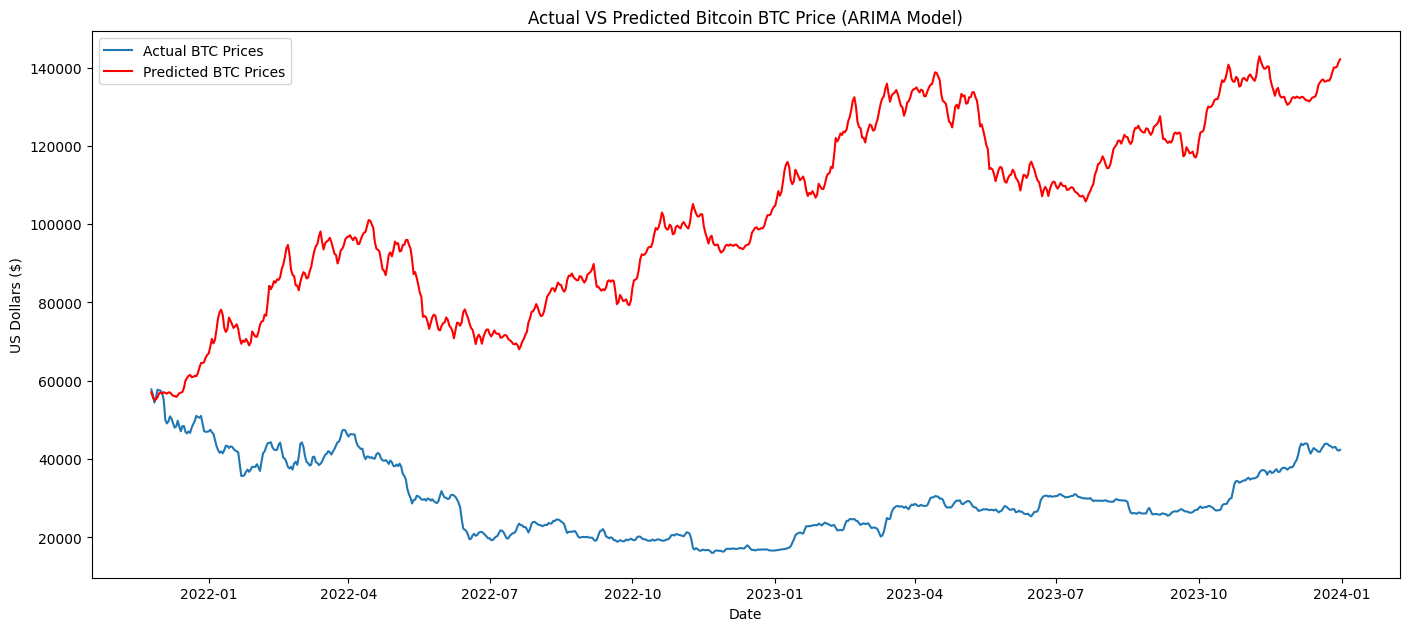

In [ ]:
# evaluate forecasts
arima_rmse = sqrt(mean_squared_error(test_data, arima_btc_predictions))
print('Test RMSE for ARIMA on BTC: %.3f' % arima_rmse, '\n')

# plot forecasts against actual outcomes
# Create the figure with the desired size
plt.figure(figsize=(14, 6))

# Plot the actual test data
plt.plot(plotDates, test_data, label='Actual BTC Prices')

# Plot the predicted data
plt.plot(plotDates, arima_btc_predictions, color='red', label='Predicted BTC Prices')

# Tighten the layout
plt.tight_layout()

# Add title and labels
plt.title('Actual VS Predicted Bitcoin BTC Price (ARIMA Model)')
plt.xlabel('Date')
plt.ylabel('US Dollars ($)')

# Add legend for clarity
plt.legend()

# Show the plot
plt.show()

# Rolling Forecast ARIMA Model


In [ ]:
# Rolling Forecast ARIMA Model
!pip install pmdarima
!pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 17.4 MB/s eta 0:00:00


In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from pmdarima import auto_arima

In [ ]:
rfarima_btc = btc['Weighted_Price']

# Split the dataset into 70% training data and 30% testing data
X_values = rfarima_btc.values
datesX = rfarima_btc.index
split_index = int(len(X_values) * 0.7)
train_data, test_data = X_values[:split_index], X_values[split_index:]
plotDates = datesX[split_index:len(X_values)]

# Initialize the training history with the training data
training_history = list(train_data)

# Create an empty list to store future predictions
rfarima_btc_predictions = []
len(test_data)

767

In [ ]:
# Walk-forward validation
for t in range(len(test_data)):
    # Fit ARIMA model on the current history (rolling)
    model = ARIMA(training_history, order=(5,1,0))
    model_fit = model.fit()

    # Make one-step-ahead prediction
    predicted_value = model_fit.forecast()
    btc_next_value = predicted_value[0]
    rfarima_btc_predictions.append(btc_next_value)

    # Get the actual value from the test set and append to history for next iteration
    actual_value = test_data[t]
    training_history.append(actual_value)

    print(f'Predicted={btc_next_value:.6f}, Expected={actual_value:.6f}')

len(rfarima_btc_predictions)

Predicted=56922.880270, Expected=57738.687500
Predicted=58074.250055, Expected=56320.824219
Predicted=55321.233198, Expected=54387.280273
Predicted=53857.978032, Expected=55758.014648
Predicted=56834.409338, Expected=57690.969727
Predicted=58065.009493, Expected=57501.555664
Predicted=56974.398445, Expected=57433.139648
Predicted=57678.120474, Expected=56734.888672
Predicted=56424.810572, Expected=55021.541016
Predicted=54362.589569, Expected=49926.969727
Predicted=47615.549140, Expected=49049.002930
Predicted=49782.016049, Expected=49551.665039
Predicted=49394.984344, Expected=50848.125977
Predicted=51172.297915, Expected=50277.452148
Predicted=49640.916537, Expected=49069.429688
Predicted=48746.764796, Expected=47981.100586
Predicted=47722.020228, Expected=48256.924805
Predicted=48562.319736, Expected=49725.977539
Predicted=50259.022694, Expected=48238.017578
Predicted=47055.057546, Expected=47044.587891
Predicted=46990.041049, Expected=48355.599609
Predicted=49236.164019, Expected=4

767

In [ ]:
len(rfarima_btc_predictions)

767

Test RMSE for Rolling Forecast ARIMA on BTC: 589.074 



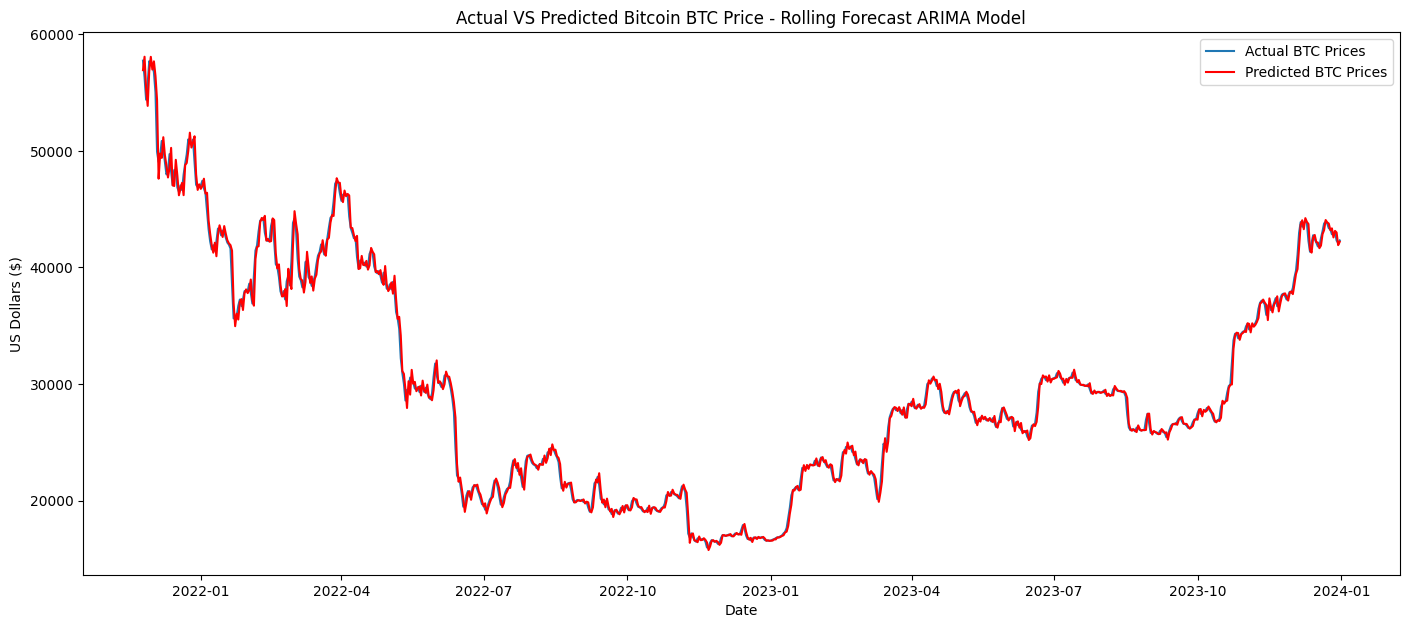

In [ ]:
# evaluate forecasts
rfarima_rmse = sqrt(mean_squared_error(test_data, rfarima_btc_predictions))
print('Test RMSE for Rolling Forecast ARIMA on BTC: %.3f' % rfarima_rmse, '\n')

# plot forecasts against actual outcomes
# Create the figure with the desired size
plt.figure(figsize=(14, 6))

# Plot the actual test data
plt.plot(plotDates, test_data, label='Actual BTC Prices')

# Plot the predicted data
plt.plot(plotDates, rfarima_btc_predictions, color='red', label='Predicted BTC Prices')

# Tighten the layout
plt.tight_layout()

# Add title and labels
plt.title('Actual VS Predicted Bitcoin BTC Price - Rolling Forecast ARIMA Model')
plt.xlabel('Date')
plt.ylabel('US Dollars ($)')

# Add legend for clarity
plt.legend()

# Show the plot
plt.show()

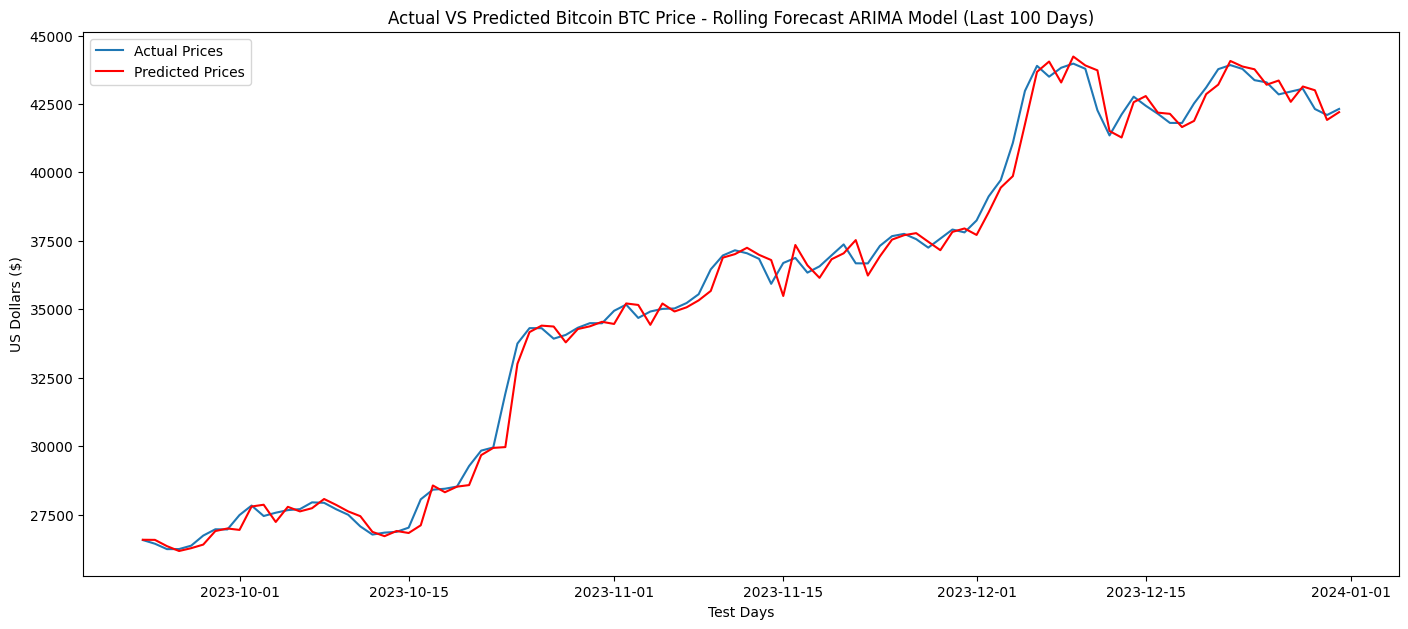

In [ ]:
# Plot only the last 100 days for better understanding
last_100_days = 100

# Slice the last 100 days of actual and predicted data
last_100_dates = plotDates[-100:]
test_data_100 = test_data[-last_100_days:]
rfarima_btc_predictions_100 = rfarima_btc_predictions[-last_100_days:]

plt.figure(figsize=(14, 6))
# Plot the actual test data for the last 100 days
plt.plot(last_100_dates, test_data_100, label='Actual Prices')

# Plot the predicted data for the last 100 days
plt.plot(last_100_dates, rfarima_btc_predictions_100, color='red', label='Predicted Prices')

# Tighten the layout
plt.tight_layout()

# Add title and labels
plt.title('Actual VS Predicted Bitcoin BTC Price - Rolling Forecast ARIMA Model (Last 100 Days)')
plt.xlabel('Test Days')
plt.ylabel('US Dollars ($)')

# Add legend for clarity
plt.legend()

# Show the plot
plt.show()

# LSTM Model


In [ ]:
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout

In [ ]:
lstm_btc = btc['Weighted_Price']

# Split the dataset into 70% training data and 30% testing data
X_values = lstm_btc.values
datesX = lstm_btc.index
split_index = int(len(X_values) * 0.7)
train_data, test_data = X_values[:split_index], X_values[split_index:]
plotDates = datesX[split_index:len(X_values)]

# Reshape training data
train_values = np.reshape(train_data, (len(train_data), 1))

# Apply MinMaxScaler to normalize the training data
scaler = MinMaxScaler()
scaled_train_values = scaler.fit_transform(train_values)

# Create input (x_train) and output (y_train) for the LSTM model
x_train = scaled_train_values[:-1]
y_train = scaled_train_values[1:]
x_train = np.reshape(x_train, (len(x_train), 1, 1))

# Reshape testing data
test_values = np.reshape(test_data, (len(test_data), 1))
test_values = scaler.transform(test_values)
test_values = np.reshape(test_values, (len(test_values), 1, 1))

len(test_data)
lstm_btc

,Weighted_Price
Date,
2017-01-02 00:00:00+00:00,1012.114761
2017-01-03 00:00:00+00:00,1032.779968
2017-01-04 00:00:00+00:00,1100.737518
2017-01-05 00:00:00+00:00,1067.906738
2017-01-06 00:00:00+00:00,961.798752
...,...
2023-12-27 00:00:00+00:00,42953.016602
2023-12-28 00:00:00+00:00,43054.846680
2023-12-29 00:00:00+00:00,42315.608398


In [ ]:
# Build the LSTM model
model = Sequential()
model.add(LSTM(units=50, return_sequences=True, activation="relu", input_shape=(None, 1)))
model.add(Dropout(0.2))
model.add(LSTM(units=50, return_sequences=False))
model.add(Dropout(0.2))
model.add(Dense(units=25))
model.add(Dense(units=1))

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

# Train the model
model.fit(x_train, y_train, batch_size=64, epochs=100)

/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0832
Epoch 2/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0459
Epoch 3/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0168
Epoch 4/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0024
Epoch 5/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0020
Epoch 6/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0020
Epoch 7/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0017
Epoch 8/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0018
Epoch 9/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0016
Epoch 10/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0020
Epoch 11/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0015
Epoch 12/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0017
Epoch 13/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0015
Epoch 14/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0014
Epoch 15/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0015
Epoc

In [ ]:
# Predict values + reshaping + converting back from scaler
lstm_btc_predictions = model.predict(test_values)
lstm_btc_predictions = np.reshape(lstm_btc_predictions, (len(lstm_btc_predictions), 1))
lstm_btc_predictions = scaler.inverse_transform(lstm_btc_predictions)

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step


Test RMSE for LSTM on BTC: 829.669 



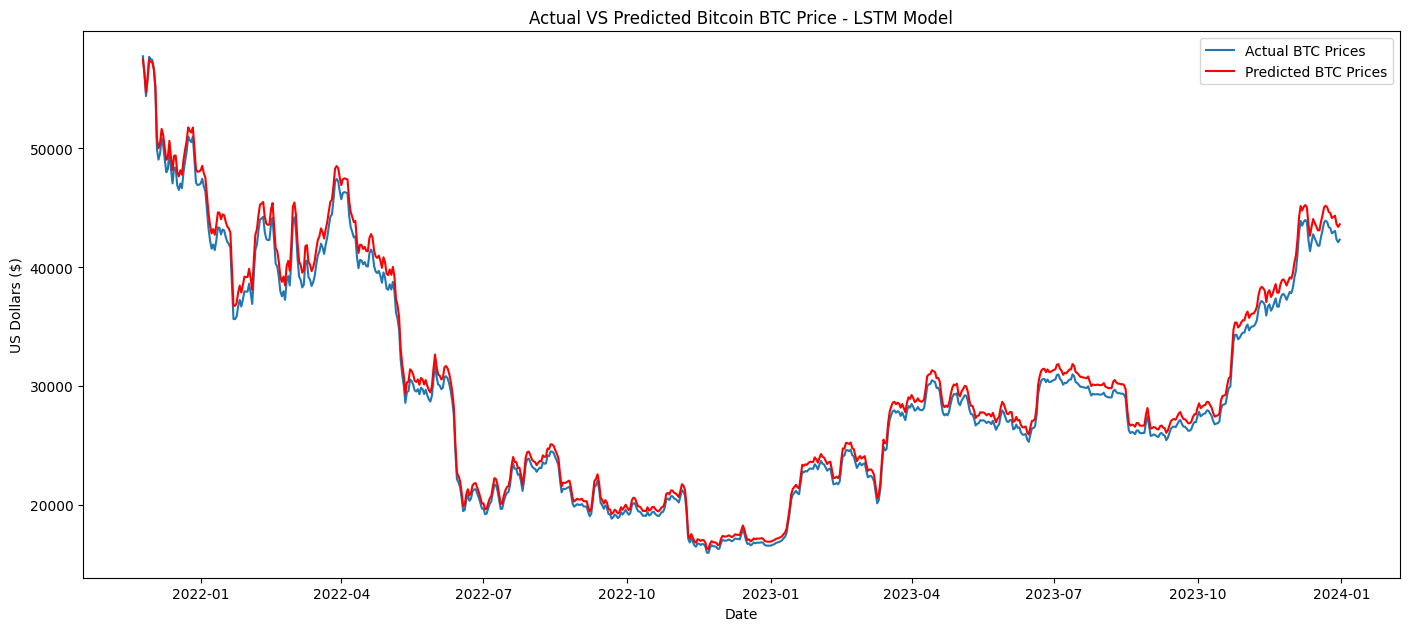

In [ ]:
# evaluate forecasts
lstm_rmse = sqrt(mean_squared_error(test_data, lstm_btc_predictions))
print('Test RMSE for LSTM on BTC: %.3f' % lstm_rmse, '\n')

# plot forecasts against actual outcomes
# Create the figure with the desired size
plt.figure(figsize=(14, 6))

# Plot the actual test data
plt.plot(plotDates, test_data, label='Actual BTC Prices')

# Plot the predicted data
plt.plot(plotDates, lstm_btc_predictions, color='red', label='Predicted BTC Prices')

# Tighten the layout
plt.tight_layout()

# Add title and labels
plt.title('Actual VS Predicted Bitcoin BTC Price - LSTM Model')
plt.xlabel('Date')
plt.ylabel('US Dollars ($)')

# Add legend for clarity
plt.legend()

# Show the plot
plt.show()

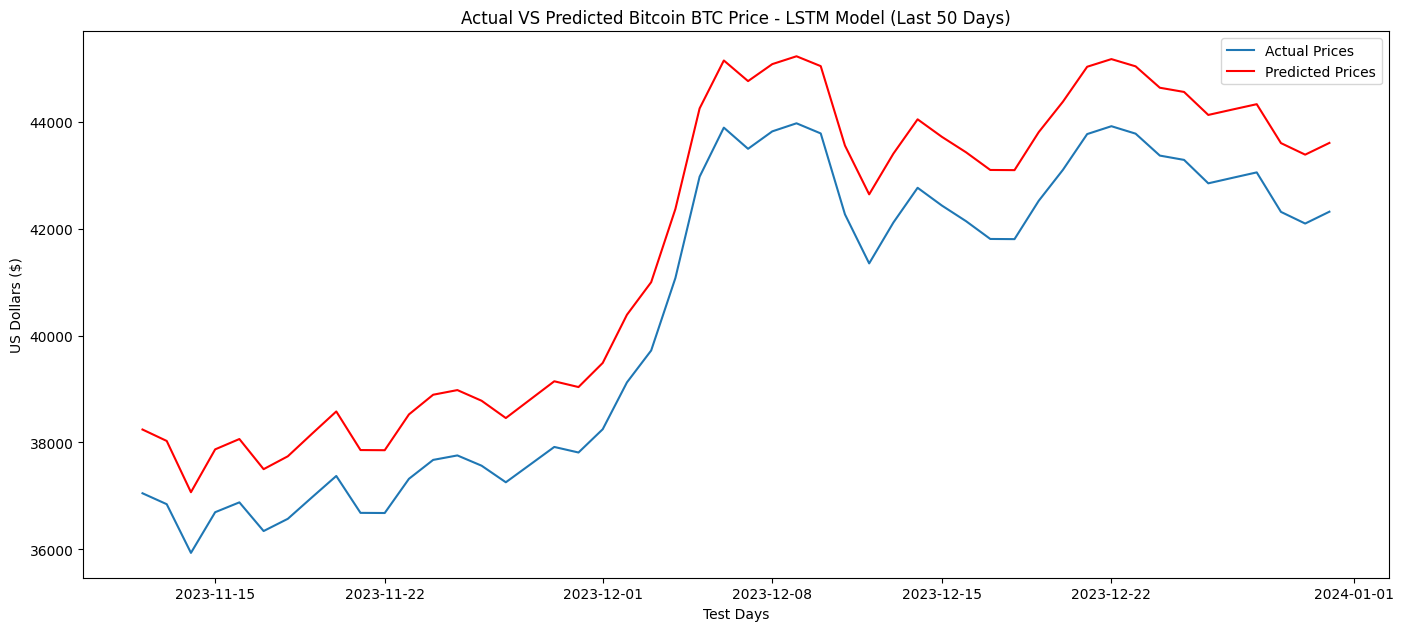

In [ ]:
# Plot only the last 50 days for better understanding
last_50_days = 50

# Slice the last 50 days of actual and predicted data
last_50_dates = plotDates[-50:]
test_data_50 = test_data[-last_50_days:]
lstm_btc_predictions_50 = lstm_btc_predictions[-last_50_days:]

plt.figure(figsize=(14, 6))
# Plot the actual test data for the last 50 days
plt.plot(last_50_dates, test_data_50, label='Actual Prices')

# Plot the predicted data for the last 50 days
plt.plot(last_50_dates, lstm_btc_predictions_50, color='red', label='Predicted Prices')

# Tighten the layout
plt.tight_layout()

# Add title and labels
plt.title('Actual VS Predicted Bitcoin BTC Price - LSTM Model (Last 50 Days)')
plt.xlabel('Test Days')
plt.ylabel('US Dollars ($)')

# Add legend for clarity
plt.legend()

# Show the plot
plt.show()

# XGBOOST Model

In [ ]:
import xgboost as xgb

In [ ]:
# Creating features for xgboost_btc
xgboost_btc = btc.copy()
xgboost_btc['Date'] = xgboost_btc.index
xgboost_btc['DayOfWeek'] = xgboost_btc['Date'].dt.dayofweek
xgboost_btc['DayOfMonth'] = xgboost_btc['Date'].dt.day
xgboost_btc['DayOfYear'] = xgboost_btc['Date'].dt.dayofyear
xgboost_btc['Month'] = xgboost_btc['Date'].dt.month
xgboost_btc['Year'] = xgboost_btc['Date'].dt.year

# Convert 'Date' to numerical representation using timestamp
xgboost_btc['Date'] = xgboost_btc['Date'].apply(pd.Timestamp.timestamp)

# splitting data again, 70, 30
split_index = int(len(xgboost_btc) * 0.7)
train_data, test_data = xgboost_btc[0:split_index], xgboost_btc[split_index:len(xgboost_btc)]
datesX = xgboost_btc.index
plotDates = datesX[split_index:len(xgboost_btc['Weighted_Price'].values)]

# Define the target (y) and the features (X) of train_data
X_train_data = train_data[['Date', 'DayOfWeek', 'DayOfMonth', 'DayOfYear', 'Month', 'Year']].values
y_train_data = train_data['Weighted_Price'].values

# Define the target (y) and the features (X) of test_data
X_test_data = test_data[['Date', 'DayOfWeek', 'DayOfMonth', 'DayOfYear', 'Month', 'Year']].values
y_test_data = test_data['Weighted_Price'].values

In [ ]:
model = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=1000, learning_rate=0.01)
model.fit(X_train_data, y_train_data)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.01, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=1000, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

In [ ]:
xgboost_btc_predictions = model.predict(X_test_data)

# Check the shape of predictions and X_test_data and y_test_data
print("X_test_data shape:", X_test_data.shape)  # Should be (rows, 6)
print("Predictions shape:", xgboost_btc_predictions.shape)  # Should be (rows,)
print("Predictions shape:", y_test_data.shape)
print("Predictions shape:", plotDates.shape) # Should be (rows,)

X_test_data shape: (767, 6)
Predictions shape: (767,)
Predictions shape: (767,)
Predictions shape: (767,)


Test RMSE for LSTM on BTC: 25765.605 



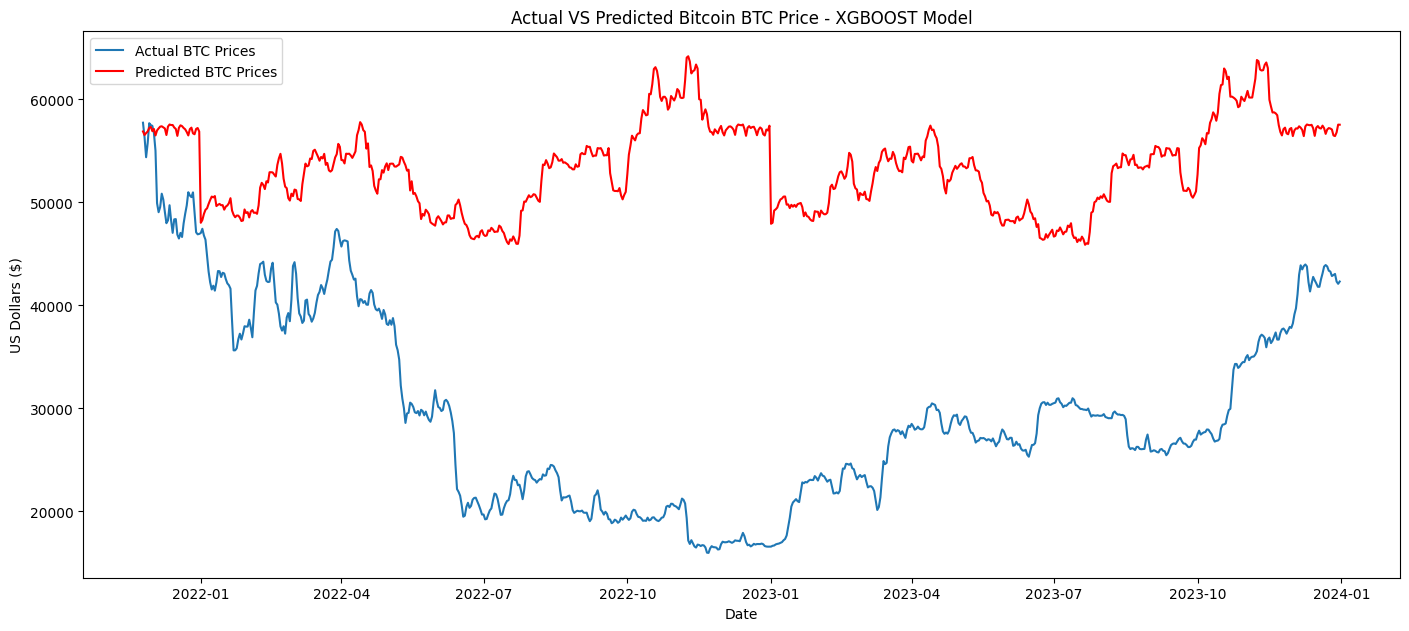

In [ ]:
# evaluate forecasts
xgboost_rmse = sqrt(mean_squared_error(y_test_data, xgboost_btc_predictions))
print('Test RMSE for LSTM on BTC: %.3f' % xgboost_rmse, '\n')

# plot forecasts against actual outcomes
# Create the figure with the desired size
plt.figure(figsize=(14, 6))

# Plot the actual test data
plt.plot(plotDates, y_test_data, label='Actual BTC Prices')

# Plot the predicted data
plt.plot(plotDates, xgboost_btc_predictions, color='red', label='Predicted BTC Prices')

# Tighten the layout
plt.tight_layout()

# Add title and labels
plt.title('Actual VS Predicted Bitcoin BTC Price - XGBOOST Model')
plt.xlabel('Date')
plt.ylabel('US Dollars ($)')

# Add legend for clarity
plt.legend()

# Show the plot
plt.show()

# Comparison among Models

Test RMSE for ARIMA on BTC: 77628.313 

Test RMSE for Rolling Forecast ARIMA on BTC: 589.074 

Test RMSE for LSTM on BTC: 829.669 

Test RMSE for XGBoost on BTC: 25765.605 



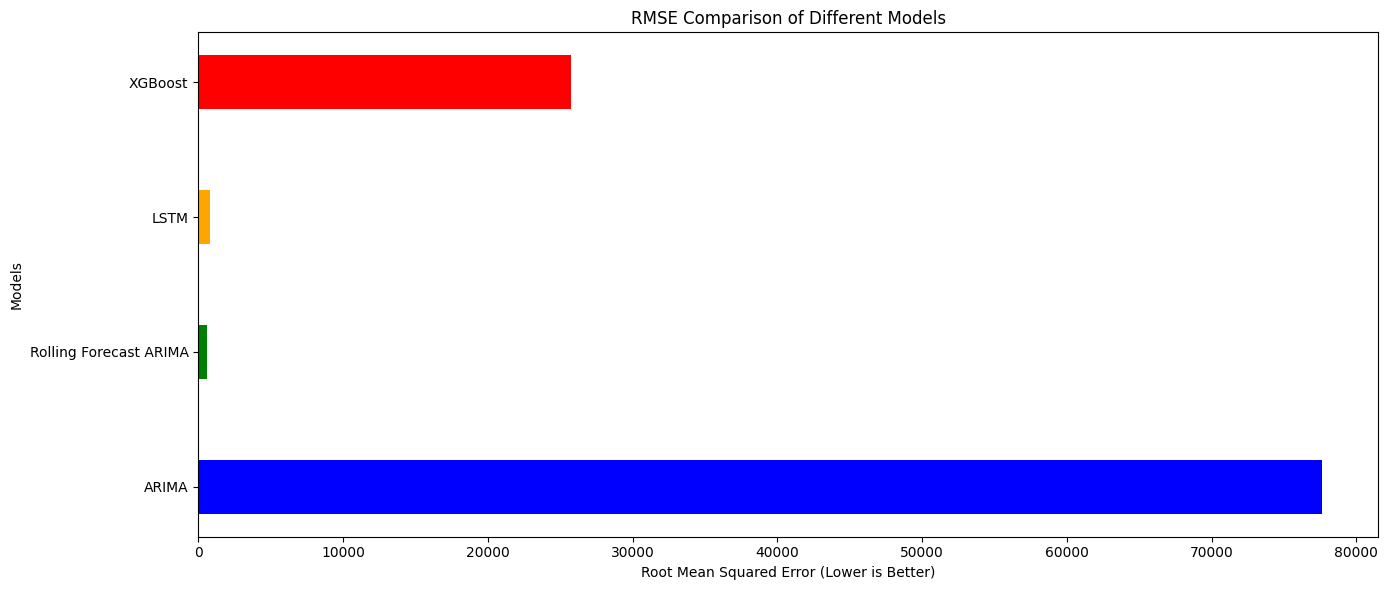

In [ ]:
# List of model names
models = ['ARIMA', 'Rolling Forecast ARIMA', 'LSTM', 'XGBoost']

# Corresponding RMSE values
rmse_values = [arima_rmse, rfarima_rmse, lstm_rmse, xgboost_rmse]

print('Test RMSE for ARIMA on BTC: %.3f' % arima_rmse, '\n')
print('Test RMSE for Rolling Forecast ARIMA on BTC: %.3f' % rfarima_rmse, '\n')
print('Test RMSE for LSTM on BTC: %.3f' % lstm_rmse, '\n')
print('Test RMSE for XGBoost on BTC: %.3f' % xgboost_rmse, '\n')

# Create a horizontal bar chart
plt.figure(figsize=(14, 6))  # Adjust figure size if necessary
plt.barh(models, rmse_values, color=['blue', 'green', 'orange', 'red'], height=0.4)

# Add title and labels
plt.title('RMSE Comparison of Different Models')
plt.xlabel('Root Mean Squared Error (Lower is Better)')
plt.ylabel('Models')

# Display the plot
plt.tight_layout()
plt.show()

# LSTM Hypertune


In [ ]:
!pip install keras-tuner

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.optimizers import Adam
from keras_tuner import RandomSearch
from sklearn.metrics import mean_squared_error
from math import sqrt
import numpy as np
import matplotlib.pyplot as plt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.1/129.1 kB 2.6 MB/s eta 0:00:00


In [ ]:
# Define the model creation function for tuning
def create_model(hp):
    model = Sequential()
    units = hp.Int('units', min_value=50, max_value=100, step=25)
    dropout_rate = hp.Float('dropout_rate', min_value=0.2, max_value=0.5, step=0.1)
    learning_rate = hp.Choice('learning_rate', values=[1e-3, 5e-4])

    model.add(LSTM(units=units, return_sequences=True, activation="relu", input_shape=(None, 1)))
    model.add(Dropout(dropout_rate))
    model.add(LSTM(units=units, return_sequences=False))
    model.add(Dropout(dropout_rate))
    model.add(Dense(units=25))
    model.add(Dense(units=1))

    optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='mean_squared_error')
    return model

In [ ]:

# Prepare data for training and testing
lstm_btc = btc['Weighted_Price']
X_values = lstm_btc.values
datesX = lstm_btc.index
split_index = int(len(X_values) * 0.7)
train_data, test_data = X_values[:split_index], X_values[split_index:]
plotDates = datesX[split_index:len(X_values)]

In [ ]:
# Reshape training data
train_values = np.reshape(train_data, (len(train_data), 1))
scaler = MinMaxScaler()
scaled_train_values = scaler.fit_transform(train_values)

# Prepare x_train and y_train for training
x_train = scaled_train_values[:-1]
y_train = scaled_train_values[1:]
x_train = np.reshape(x_train, (len(x_train), 1, 1))


In [ ]:
# Set up keras-tuner RandomSearch
tuner = RandomSearch(
    create_model,
    objective='val_loss',
    max_trials=5,
    executions_per_trial=1,
    directory='tuner_dir',
    project_name='lstm_btc_tuning'
)

# Perform hyperparameter search
tuner.search(x_train, y_train, epochs=50, batch_size=32, validation_split=0.2)

# Get the best model
best_model = tuner.get_best_models(num_models=1)[0]

# Prepare test data for prediction
test_values = np.reshape(test_data, (len(test_data), 1))
scaled_test_values = scaler.transform(test_values)
scaled_test_values = np.reshape(scaled_test_values, (len(scaled_test_values), 1, 1))

# Predict and inverse transform the results
lstm_btc_predictions = best_model.predict(scaled_test_values)
lstm_btc_predictions = scaler.inverse_transform(lstm_btc_predictions)


Trial 5 Complete [00h 00m 19s]
val_loss: 0.0004364456108305603

Best val_loss So Far: 0.0004055452882312238
Total elapsed time: 00h 01m 57s


/usr/local/lib/python3.10/dist-packages/keras/src/saving/saving_lib.py:576: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step


Test RMSE for Optimized LSTM on BTC: 127.304


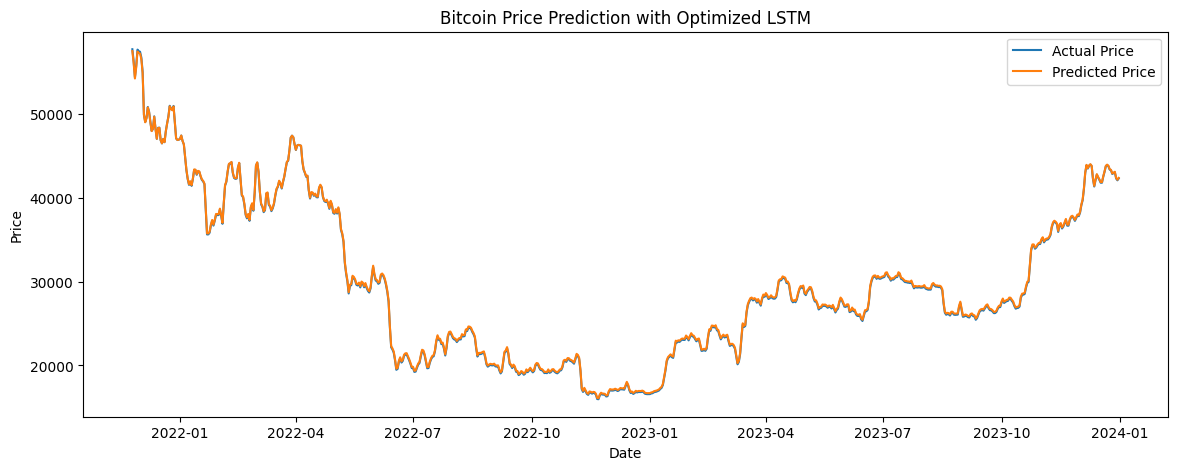

In [ ]:
# Evaluate forecasts with RMSE
lstm_rmse = sqrt(mean_squared_error(test_data, lstm_btc_predictions))
print('Test RMSE for Optimized LSTM on BTC: %.3f' % lstm_rmse)

# Plotting the actual vs. predicted prices (optional)
plt.figure(figsize=(14,5))
plt.plot(plotDates, test_data, label='Actual Price')
plt.plot(plotDates, lstm_btc_predictions, label='Predicted Price')
plt.title('Bitcoin Price Prediction with Optimized LSTM')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.show()

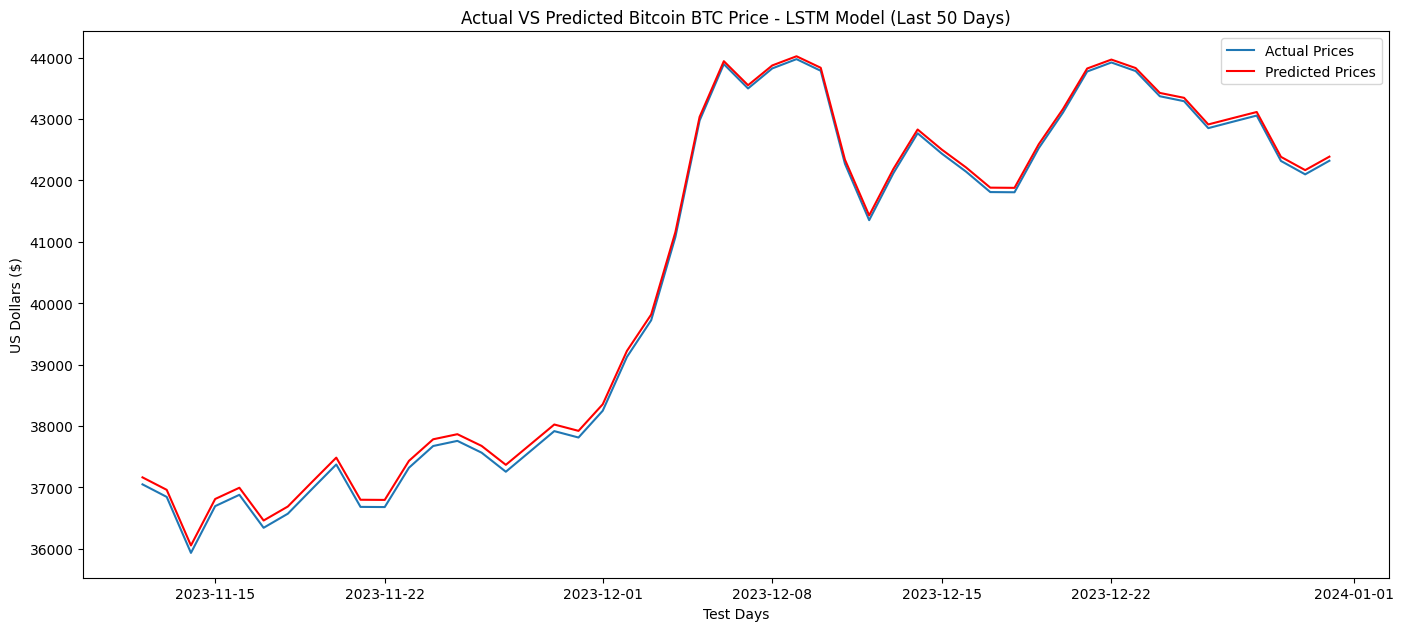

In [ ]:
# Plot only the last 50 days for better understanding
last_50_days = 50

# Slice the last 50 days of actual and predicted data
last_50_dates = plotDates[-50:]
test_data_50 = test_data[-last_50_days:]
lstm_btc_predictions_50 = lstm_btc_predictions[-last_50_days:]

plt.figure(figsize=(14, 6))
# Plot the actual test data for the last 50 days
plt.plot(last_50_dates, test_data_50, label='Actual Prices')

# Plot the predicted data for the last 50 days
plt.plot(last_50_dates, lstm_btc_predictions_50, color='red', label='Predicted Prices')

# Tighten the layout
plt.tight_layout()

# Add title and labels
plt.title('Actual VS Predicted Bitcoin BTC Price - LSTM Model (Last 50 Days)')
plt.xlabel('Test Days')
plt.ylabel('US Dollars ($)')

# Add legend for clarity
plt.legend()

# Show the plot
plt.show()